In [2]:
import numpy as np
import pandas as pd
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo, list_available_datasets
import matplotlib.pyplot as plt

# Lab 03 - Logistic Regression

Link to dataset: https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records

In [3]:
list_available_datasets()

-------------------------------------
The following datasets are available:
-------------------------------------
Dataset Name                                                                            ID    
------------                                                                            --    
Abalone                                                                                 1     
Adult                                                                                   2     
Annealing                                                                               3     
Audiology (Standardized)                                                                8     
Auto MPG                                                                                9     
Automobile                                                                              10    
Balance Scale                                                                           12    
Balloons                       

In [4]:
# We use dataset Heart Failure Clinical Records Dataset (ID: 519)
# Reference: https://bmcmedinformdecismak.biomedcentral.com/articles/10.1186/s12911-020-1023-5

# fetch dataset
heart_failure_clinical_records = fetch_ucirepo(id=519)

# data (as pandas dataframes)
X = heart_failure_clinical_records.data.features
y = heart_failure_clinical_records.data.targets

In [5]:
# metadata
heart_failure_clinical_records.metadata

{'uci_id': 519,
 'name': 'Heart Failure Clinical Records',
 'repository_url': 'https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records',
 'data_url': 'https://archive.ics.uci.edu/static/public/519/data.csv',
 'abstract': 'This dataset contains the medical records of 299 patients who had heart failure, collected during their follow-up period, where each patient profile has 13 clinical features.',
 'area': 'Health and Medicine',
 'tasks': ['Classification', 'Regression', 'Clustering'],
 'characteristics': ['Multivariate'],
 'num_instances': 299,
 'num_features': 12,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Age', 'Sex'],
 'target_col': ['death_event'],
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2020,
 'last_updated': 'Mon Feb 26 2024',
 'dataset_doi': '10.24432/C5Z89R',
 'creators': [],
 'intro_paper': {'ID': 286,
  'type': 'NATIVE',
  'title': 'Machine learning can predict survival of patie

In [6]:
# variable information
heart_failure_clinical_records.variables

,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,age of the patient,years,no
1,anaemia,Feature,Binary,None,decrease of red blood cells or hemoglobin,None,no
2,creatinine_phosphokinase,Feature,Integer,None,level of the CPK enzyme in the blood,mcg/L,no
3,diabetes,Feature,Binary,None,if the patient has diabetes,None,no
4,ejection_fraction,Feature,Integer,None,percentage of blood leaving the heart at each ...,%,no
5,high_blood_pressure,Feature,Binary,None,if the patient has hypertension,None,no
6,platelets,Feature,Continuous,None,platelets in the blood,kiloplatelets/mL,no
7,serum_creatinine,Feature,Continuous,None,level of serum creatinine in the blood,mg/dL,no
8,serum_sodium,Feature,Integer,None,level of serum sodium in the blood,mEq/L,no
9,sex,Feature,Binary,Sex,woman or man,None,no


In [7]:
X.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8


In [8]:
y.head()

,death_event
0,1
1,1
2,1
3,1
4,1


## 1. Первичный анализ данных

In [9]:
# Размеры данных
print("Признаки X:", X.shape)
print("Целевая переменная y:", y.shape)
print()
print("Пропущенные значения в X:", X.isnull().sum().sum())
print("Пропущенные значения в y:", y.isnull().sum().sum())

Признаки X: (299, 12)
Целевая переменная y: (299, 1)

Пропущенные значения в X: 0
Пропущенные значения в y: 0


In [10]:
# Типы данных
X.dtypes

,0
age,float64
anaemia,int64
creatinine_phosphokinase,int64
diabetes,int64
ejection_fraction,int64
high_blood_pressure,int64
platelets,float64
serum_creatinine,float64
serum_sodium,int64
sex,int64


In [11]:
# Статистика по признакам
X.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000


In [12]:
# Целевая переменная: death_event (1 - пациент умер, 0 - выжил)
# превращаем y из таблицы в обычный одномерный массив
y = y['death_event']

print(y.value_counts())
print()
print("Доля умерших:", round(y.mean(), 3))
print("Доля выживших:", round(1 - y.mean(), 3))

death_event
0    203
1     96
Name: count, dtype: int64

Доля умерших: 0.321
Доля выживших: 0.679


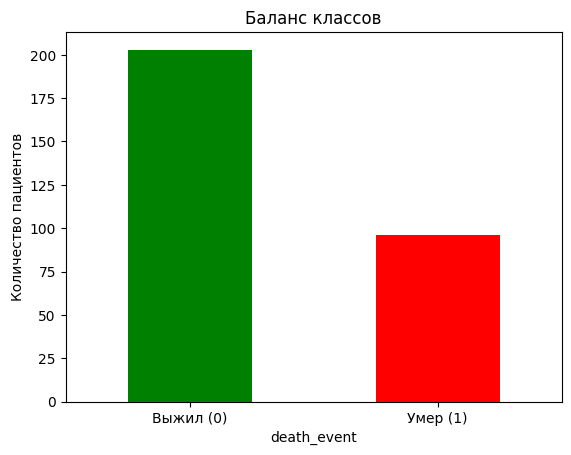

In [13]:
# График баланса классов
y.value_counts().sort_index().plot(kind='bar', color=['green', 'red'])
plt.xticks([0, 1], ['Выжил (0)', 'Умер (1)'], rotation=0)
plt.ylabel('Количество пациентов')
plt.title('Баланс классов')
plt.show()

time                       -0.527
ejection_fraction          -0.269
serum_sodium               -0.195
platelets                  -0.049
smoking                    -0.013
sex                        -0.004
diabetes                   -0.002
creatinine_phosphokinase    0.063
anaemia                     0.066
high_blood_pressure         0.079
age                         0.254
serum_creatinine            0.294
dtype: float64


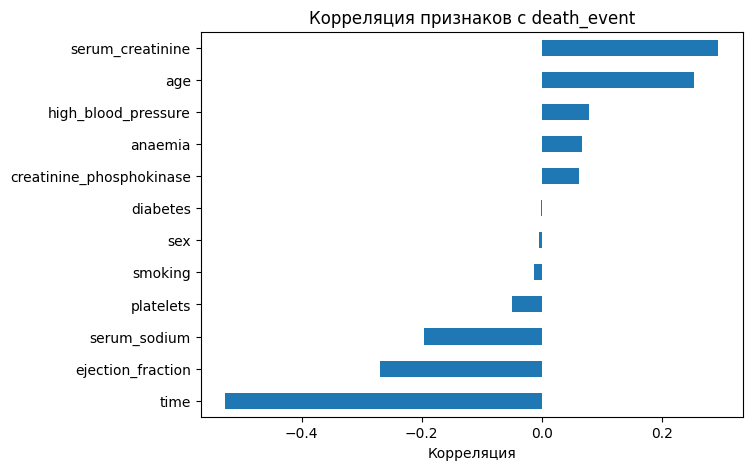

In [14]:
# Корреляция каждого признака с death_event
corr_with_target = X.corrwith(y).sort_values()
print(corr_with_target.round(3))

corr_with_target.plot(kind='barh', figsize=(7, 5))
plt.title('Корреляция признаков с death_event')
plt.xlabel('Корреляция')
plt.show()

## 2. Разделение данных на train и test

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

In [16]:
# stratify=y сохраняет одинаковую долю умерших и в train, и в test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| доля умерших:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| доля умерших:", round(y_test.mean(), 3))

Train: (239, 12) | доля умерших: 0.322
Test:  (60, 12) | доля умерших: 0.317


## 3. Масштабирование признаков

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Обучение модели

In [18]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

## 5. Предсказания и оценка

In [19]:
# Предсказанные классы (0 или 1)
y_pred = model.predict(X_test_scaled)

# Предсказанные вероятности смерти (для ROC-кривой)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Настоящие:   ", y_test.values[:10])
print("Предсказано: ", y_pred[:10])
print("Вероятности: ", y_proba[:10].round(2))

Настоящие:    [0 0 0 0 0 0 0 1 0 0]
Предсказано:  [0 0 0 0 0 0 0 0 0 0]
Вероятности:  [0.05 0.24 0.1  0.11 0.09 0.   0.04 0.13 0.01 0.28]


In [20]:
# Основные метрики
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("Accuracy: ", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:   ", round(recall, 4))
print("F1:       ", round(f1, 4))
print("ROC AUC:  ", round(auc, 4))

Accuracy:  0.8167
Precision: 0.7857
Recall:    0.5789
F1:        0.6667
ROC AUC:   0.8588


In [21]:
# Базовый уровень: что если всегда предсказывать "выжил" (самый частый класс)?
baseline_accuracy = 1 - y_test.mean()
print("Accuracy базовой модели (всегда 'выжил'):", round(baseline_accuracy, 4))
print("Accuracy нашей модели:                   ", round(accuracy, 4))

Accuracy базовой модели (всегда 'выжил'): 0.6833
Accuracy нашей модели:                    0.8167
